### Análisis de ventas de variantes de café (PySpark)

In [2]:
# Importación de librerías
import pyspark
from pyspark.sql import SparkSession, Row
from pyspark.sql.functions import round, col
from pyspark.sql.types import IntegerType, FloatType, StringType

In [ ]:
# Generación de la sesión Spark y lectura de archivos: Clientes
spark= SparkSession.builder.appName('Lectura_archivos').getOrCreate()
path= '/files/customers.csv'
df_customers= spark.read.csv(path, header= True)
df_customers.show(5)

+--------------+-------------------+--------------------+-------------------+--------------------+-----------+-------------+--------+------------+
|   Customer ID|      Customer Name|               Email|       Phone Number|      Address Line 1|       City|      Country|Postcode|Loyalty Card|
+--------------+-------------------+--------------------+-------------------+--------------------+-----------+-------------+--------+------------+
|17670-51384-MA|     Aloisia Allner|   aallner0@lulu.com|  +1 (862) 817-0124|57999 Pepper Wood...|   Paterson|United States|    7505|         Yes|
|73342-18763-UW|         Piotr Bote|     pbote1@yelp.com|+353 (913) 396-4653|  2112 Ridgeway Hill|    Crumlin|      Ireland|     D6W|          No|
|21125-22134-PX|      Jami Redholes|jredholes2@tmall.com|  +1 (210) 986-6806| 5214 Bartillon Park|San Antonio|United States|   78205|         Yes|
|71253-00052-RN|         Dene Azema|dazema3@facebook.com|  +1 (217) 418-0714|    27 Maywood Place|Springfield|United S

In [ ]:
# Órdenes
path1= '/files/orders.csv'
df_orders= spark.read.csv(path1, header= True)
df_orders.show(5)

+-----------+----------+------+----------+--------+----------------+---------------+------------+
|Coffee Type|Roast Type|  Size|Unit Price|   Sales|Coffee Type Name|Roast Type Name|Loyalty Card|
+-----------+----------+------+----------+--------+----------------+---------------+------------+
|        Rob|         M|1.0 kg|    $9.95 | $19.90 |         Robusta|         Medium|         Yes|
|        Exc|         M|0.5 kg|    $8.25 | $41.25 |         Excelsa|         Medium|         Yes|
|        Ara|         L|1.0 kg|   $12.95 | $12.95 |         Arabica|          Light|         Yes|
|        Exc|         M|1.0 kg|   $13.75 | $27.50 |         Excelsa|         Medium|          No|
|        Rob|         L|2.5 kg|   $27.49 | $54.97 |         Robusta|          Light|          No|
+-----------+----------+------+----------+--------+----------------+---------------+------------+
only showing top 5 rows



In [ ]:
# Productos
path2= path= '/files/products.csv'
df_products= spark.read.csv(path2, header= True)
df_products.show(5)

+----------+-----------+----------+----+----------+--------------+-------+
|Product ID|Coffee Type|Roast Type|Size|Unit Price|Price per 100g| Profit|
+----------+-----------+----------+----+----------+--------------+-------+
|   A-L-0.2|        Ara|         L| 0.2|     3.885|        1.9425|0.34965|
|   A-L-0.5|        Ara|         L| 0.5|      7.77|         1.554| 0.6993|
|     A-L-1|        Ara|         L| 1.0|     12.95|         1.295| 1.1655|
|   A-L-2.5|        Ara|         L| 2.5|    29.785|        1.1914|2.68065|
|   A-M-0.2|        Ara|         M| 0.2|     3.375|        1.6875|0.30375|
+----------+-----------+----------+----+----------+--------------+-------+
only showing top 5 rows



In [ ]:
# Esquemas de cada dataframe
for df in (df_customers, df_orders, df_products):
    df.printSchema()

root
 |-- Customer ID: string (nullable = true)
 |-- Customer Name: string (nullable = true)
 |-- Email: string (nullable = true)
 |-- Phone Number: string (nullable = true)
 |-- Address Line 1: string (nullable = true)
 |-- City: string (nullable = true)
 |-- Country: string (nullable = true)
 |-- Postcode: string (nullable = true)
 |-- Loyalty Card: string (nullable = true)

root
 |-- Coffee Type: string (nullable = true)
 |-- Roast Type: string (nullable = true)
 |-- Size: string (nullable = true)
 |-- Unit Price: string (nullable = true)
 |-- Sales: string (nullable = true)
 |-- Coffee Type Name: string (nullable = true)
 |-- Roast Type Name: string (nullable = true)
 |-- Loyalty Card: string (nullable = true)

root
 |-- Product ID: string (nullable = true)
 |-- Coffee Type: string (nullable = true)
 |-- Roast Type: string (nullable = true)
 |-- Size: string (nullable = true)
 |-- Unit Price: string (nullable = true)
 |-- Price per 100g: string (nullable = true)
 |-- Profit: string

In [ ]:
# Búsqueda de nulos en Clientes
from pyspark.sql import functions as F
for c in df_customers.columns:
    print(c, df_customers.filter(F.col(c).isNull()).count())

Customer ID 0
Customer Name 0
Email 204
Phone Number 130
Address Line 1 0
City 0
Country 0
Postcode 0
Loyalty Card 0


In [ ]:
# Búsqueda de nulos en Productos
for c in df_products.columns:
    print(c, df_products.filter(F.col(c).isNull()).count())

Product ID 0
Coffee Type 0
Roast Type 0
Size 0
Unit Price 0
Price per 100g 0
Profit 0


In [ ]:
# Búsqueda de nulos en Órdenes
for c in df_orders.columns:
    print(c, df_orders.filter(F.col(c).isNull()).count())

Coffee Type 0
Roast Type 0
Size 0
Unit Price 0
Sales 0
Coffee Type Name 0
Roast Type Name 0
Loyalty Card 0


In [6]:
# Se elimina el caracter $ de los precios y ventas en el dataframe de órdenes
from pyspark.sql.functions import regexp_replace
for c in ('Unit Price', 'Sales'):
    df_orders= df_orders.withColumn(c, regexp_replace(c, r'[\$,]', ''))


In [7]:
# Transformación de columnas sin $ a numéricas
for c in ('Unit Price', 'Sales'):
    df_orders= df_orders.withColumn(c, col(c).cast('float'))

In [8]:
# Transformación de columnas numéricas en el dataframe de productos
for c in ('Size', 'Unit Price', 'Price per 100g', 'Profit'):
    df_products= df_products.withColumn(c, col(c).cast('float'))

In [10]:
# Estadísticas de los dataframes
for df in (df_customers, df_products, df_orders):
    print(df.describe().show())

+-------+--------------+--------------+--------------------+------------------+-------------------+-----------+-------------+-----------------+------------+
|summary|   Customer ID| Customer Name|               Email|      Phone Number|     Address Line 1|       City|      Country|         Postcode|Loyalty Card|
+-------+--------------+--------------+--------------------+------------------+-------------------+-----------+-------------+-----------------+------------+
|  count|          1000|          1000|                 796|               870|               1000|       1000|         1000|             1000|        1000|
|   mean|          NULL|          NULL|                NULL|              NULL|               NULL|       NULL|         NULL|53430.04987212276|        NULL|
| stddev|          NULL|          NULL|                NULL|              NULL|               NULL|       NULL|         NULL|28907.59564018794|        NULL|
|    min|00246-15080-LE|  Abba Pummell|aadamidesco@bizjo..

In [13]:
# Búsqueda de duplicados
for df in (df_customers, df_orders, df_products):
    print(df.exceptAll(df.dropDuplicates()).count())

0
519
0


In [10]:
# Filtro de filas duplicadas en la tabla de órdenes
drop_dups= df_orders.dropDuplicates()
drop_dups.show()

+-----------+----------+------+----------+------+----------------+---------------+------------+
|Coffee Type|Roast Type|  Size|Unit Price| Sales|Coffee Type Name|Roast Type Name|Loyalty Card|
+-----------+----------+------+----------+------+----------------+---------------+------------+
|        Exc|         M|1.0 kg|     13.75|  27.5|         Excelsa|         Medium|          No|
|        Lib|         L|0.2 kg|      4.76| 19.02|        Liberica|          Light|         Yes|
|        Lib|         L|1.0 kg|     15.85| 15.85|        Liberica|          Light|         Yes|
|        Lib|         D|2.5 kg|     29.79| 59.57|        Liberica|           Dark|         Yes|
|        Ara|         D|0.2 kg|      2.99|  5.97|         Arabica|           Dark|         Yes|
|        Lib|         L|2.5 kg|     36.46|109.37|        Liberica|          Light|          No|
|        Rob|         L|0.5 kg|      7.17|  7.17|         Robusta|          Light|         Yes|
|        Exc|         D|0.5 kg|      7.2

In [10]:
df_orders.show()

+-----------+----------+------+----------+------+----------------+---------------+------------+
|Coffee Type|Roast Type|  Size|Unit Price| Sales|Coffee Type Name|Roast Type Name|Loyalty Card|
+-----------+----------+------+----------+------+----------------+---------------+------------+
|        Rob|         M|1.0 kg|      9.95|  19.9|         Robusta|         Medium|         Yes|
|        Exc|         M|0.5 kg|      8.25| 41.25|         Excelsa|         Medium|         Yes|
|        Ara|         L|1.0 kg|     12.95| 12.95|         Arabica|          Light|         Yes|
|        Exc|         M|1.0 kg|     13.75|  27.5|         Excelsa|         Medium|          No|
|        Rob|         L|2.5 kg|     27.49| 54.97|         Robusta|          Light|          No|
|        Lib|         D|1.0 kg|     12.95| 38.85|        Liberica|           Dark|          No|
|        Exc|         D|0.5 kg|      7.29| 21.87|         Excelsa|           Dark|         Yes|
|        Lib|         L|0.2 kg|      4.7

In [22]:
# Suma de ventas
from pyspark.sql import functions as F
orders_total= df_orders.agg(F.sum('Sales'))
orders_total.collect()[0][0]

45135.34986329079

In [11]:
# Suma de ventas sin filas duplicadas
drop_dups_total= drop_dups.agg(F.sum('Sales'))
drop_dups_total.collect()[0][0]

22086.919933080673

In [12]:
# Total de ventas en columnas duplicadas
orders_total.collect()[0][0] - drop_dups_total.collect()[0][0]

23048.429930210114

Se asume que no existen ventas duplicadas ya que el dataframe no contiene un identificador único o fecha. La suma de ventas en filas duplicadas sobrepasa las ventas.<br><br>

Se calcularán las siguientes métricas:
- Cantidad vendida: Ventas / Precio unitario 
- Margen de beneficio aplicado: Beneficio / Precio unitario 
- Beneficio total: Beneficio * Cantidad vendida
- Margen de beneficio relativo: Beneficio total / Ventas * 100

In [9]:
# Extracción de características útiles: Columna de cantidad vendida
df_orders= df_orders.withColumn('Quantity', round(col('Sales') / col('Unit Price')))
df_orders.show(5)

+-----------+----------+------+----------+-----+----------------+---------------+------------+--------+
|Coffee Type|Roast Type|  Size|Unit Price|Sales|Coffee Type Name|Roast Type Name|Loyalty Card|Quantity|
+-----------+----------+------+----------+-----+----------------+---------------+------------+--------+
|        Rob|         M|1.0 kg|      9.95| 19.9|         Robusta|         Medium|         Yes|     2.0|
|        Exc|         M|0.5 kg|      8.25|41.25|         Excelsa|         Medium|         Yes|     5.0|
|        Ara|         L|1.0 kg|     12.95|12.95|         Arabica|          Light|         Yes|     1.0|
|        Exc|         M|1.0 kg|     13.75| 27.5|         Excelsa|         Medium|          No|     2.0|
|        Rob|         L|2.5 kg|     27.49|54.97|         Robusta|          Light|          No|     2.0|
+-----------+----------+------+----------+-----+----------------+---------------+------------+--------+
only showing top 5 rows



In [10]:
# La Tasa de beneficio es el 9% del precio de venta unitario (Profit rate)
df_products= df_products.withColumn('Profit rate', round(col('Profit') / col('Unit Price'), 2))
df_products.show(5)

+----------+-----------+----------+----+----------+--------------+-------+-----------+
|Product ID|Coffee Type|Roast Type|Size|Unit Price|Price per 100g| Profit|Profit rate|
+----------+-----------+----------+----+----------+--------------+-------+-----------+
|   A-L-0.2|        Ara|         L| 0.2|     3.885|        1.9425|0.34965|       0.09|
|   A-L-0.5|        Ara|         L| 0.5|      7.77|         1.554| 0.6993|       0.09|
|     A-L-1|        Ara|         L| 1.0|     12.95|         1.295| 1.1655|       0.09|
|   A-L-2.5|        Ara|         L| 2.5|    29.785|        1.1914|2.68065|       0.09|
|   A-M-0.2|        Ara|         M| 0.2|     3.375|        1.6875|0.30375|       0.09|
+----------+-----------+----------+----+----------+--------------+-------+-----------+
only showing top 5 rows



In [11]:
from pyspark.sql.functions import concat_ws
from pyspark.sql.functions import substring

In [12]:
# Para crear un ID similar al df_products en el dataframe df_orders se extraen columnas con el primer caracter de Coffee Type
df_orders= df_orders.withColumn('Substring', substring('Coffee Type', 1, 1))
df_orders.show(5)

+-----------+----------+------+----------+-----+----------------+---------------+------------+--------+---------+
|Coffee Type|Roast Type|  Size|Unit Price|Sales|Coffee Type Name|Roast Type Name|Loyalty Card|Quantity|Substring|
+-----------+----------+------+----------+-----+----------------+---------------+------------+--------+---------+
|        Rob|         M|1.0 kg|      9.95| 19.9|         Robusta|         Medium|         Yes|     2.0|        R|
|        Exc|         M|0.5 kg|      8.25|41.25|         Excelsa|         Medium|         Yes|     5.0|        E|
|        Ara|         L|1.0 kg|     12.95|12.95|         Arabica|          Light|         Yes|     1.0|        A|
|        Exc|         M|1.0 kg|     13.75| 27.5|         Excelsa|         Medium|          No|     2.0|        E|
|        Rob|         L|2.5 kg|     27.49|54.97|         Robusta|          Light|          No|     2.0|        R|
+-----------+----------+------+----------+-----+----------------+---------------+-------

In [ ]:
# Se extraen también los tres primeros caracteres de Size
df_orders= df_orders.withColumn('Substring_size', substring('Size', 1, 3))
df_orders.show(5)

+-----------+----------+------+----------+-----+----------------+---------------+------------+--------+---------+--------------+
|Coffee Type|Roast Type|  Size|Unit Price|Sales|Coffee Type Name|Roast Type Name|Loyalty Card|Quantity|Substring|Substring_size|
+-----------+----------+------+----------+-----+----------------+---------------+------------+--------+---------+--------------+
|        Rob|         M|1.0 kg|      9.95| 19.9|         Robusta|         Medium|         Yes|     2.0|        R|           1.0|
|        Exc|         M|0.5 kg|      8.25|41.25|         Excelsa|         Medium|         Yes|     5.0|        E|           0.5|
|        Ara|         L|1.0 kg|     12.95|12.95|         Arabica|          Light|         Yes|     1.0|        A|           1.0|
|        Exc|         M|1.0 kg|     13.75| 27.5|         Excelsa|         Medium|          No|     2.0|        E|           1.0|
|        Rob|         L|2.5 kg|     27.49|54.97|         Robusta|          Light|          No|   

In [14]:
# Renombrar columna Roast Type para poder concatenar el nuevo Product ID
df_orders= df_orders.withColumnRenamed('Roast Type', 'Roast_Type')

In [15]:
# Para obtener el total de beneficio se creará la columna Product ID en el df_products concatenando los substrings anteriores
df_orders= df_orders.withColumn('Product ID' , concat_ws('-', df_orders.Substring, df_orders.Roast_Type, df_orders.Substring_size))

In [15]:
df_orders.show(5)

+-----------+----------+------+----------+-----+----------------+---------------+------------+--------+---------+--------------+----------+
|Coffee Type|Roast_Type|  Size|Unit Price|Sales|Coffee Type Name|Roast Type Name|Loyalty Card|Quantity|Substring|Substring_size|Product ID|
+-----------+----------+------+----------+-----+----------------+---------------+------------+--------+---------+--------------+----------+
|        Rob|         M|1.0 kg|      9.95| 19.9|         Robusta|         Medium|         Yes|     2.0|        R|           1.0|   R-M-1.0|
|        Exc|         M|0.5 kg|      8.25|41.25|         Excelsa|         Medium|         Yes|     5.0|        E|           0.5|   E-M-0.5|
|        Ara|         L|1.0 kg|     12.95|12.95|         Arabica|          Light|         Yes|     1.0|        A|           1.0|   A-L-1.0|
|        Exc|         M|1.0 kg|     13.75| 27.5|         Excelsa|         Medium|          No|     2.0|        E|           1.0|   E-M-1.0|
|        Rob|       

In [16]:
# Union de dataframes de Productos y órdenes, se elimina la columna Unit Price contenida de ambos dataframes
df_products_orders= df_products.join(df_orders, on= 'Product ID', how= 'inner').drop(df_products["Unit Price"])
df_products_orders.show(5)

+----------+-----------+----------+----+--------------+-------+-----------+-----------+----------+------+----------+-----+----------------+---------------+------------+--------+---------+--------------+
|Product ID|Coffee Type|Roast Type|Size|Price per 100g| Profit|Profit rate|Coffee Type|Roast_Type|  Size|Unit Price|Sales|Coffee Type Name|Roast Type Name|Loyalty Card|Quantity|Substring|Substring_size|
+----------+-----------+----------+----+--------------+-------+-----------+-----------+----------+------+----------+-----+----------------+---------------+------------+--------+---------+--------------+
|   E-M-0.5|        Exc|         M| 0.5|          1.65| 0.9075|       0.11|        Exc|         M|0.5 kg|      8.25|41.25|         Excelsa|         Medium|         Yes|     5.0|        E|           0.5|
|   R-L-2.5|        Rob|         L| 2.5|        1.0994| 1.6491|       0.06|        Rob|         L|2.5 kg|     27.49|54.97|         Robusta|          Light|          No|     2.0|        R| 

In [17]:
# Longitud del nuevo dataframe
df_products_orders.count()

764

In [18]:
# Longitud de los dataframes mezclados
print(df_products.count())
print(df_orders.count())

48
1000


In [ ]:
# Beneficio total: Beneficio x Cantidad de compra
df_products_orders= df_products_orders.withColumn('Total profit', col('Profit') * col('Quantity')) 
df_products_orders.show(5) 

+----------+-----------+----------+----+--------------+-------+-----------+-----------+----------+------+----------+-----+----------------+---------------+------------+--------+---------+--------------+------------------+
|Product ID|Coffee Type|Roast Type|Size|Price per 100g| Profit|Profit rate|Coffee Type|Roast_Type|  Size|Unit Price|Sales|Coffee Type Name|Roast Type Name|Loyalty Card|Quantity|Substring|Substring_size|      Total profit|
+----------+-----------+----------+----+--------------+-------+-----------+-----------+----------+------+----------+-----+----------------+---------------+------------+--------+---------+--------------+------------------+
|   E-M-0.5|        Exc|         M| 0.5|          1.65| 0.9075|       0.11|        Exc|         M|0.5 kg|      8.25|41.25|         Excelsa|         Medium|         Yes|     5.0|        E|           0.5|4.5375001430511475|
|   R-L-2.5|        Rob|         L| 2.5|        1.0994| 1.6491|       0.06|        Rob|         L|2.5 kg|     27

In [63]:
df_products_orders.printSchema()

root
 |-- Product ID: string (nullable = true)
 |-- Coffee Type: string (nullable = true)
 |-- Roast Type: string (nullable = true)
 |-- Size: float (nullable = true)
 |-- Price per 100g: float (nullable = true)
 |-- Profit: float (nullable = true)
 |-- Profit rate: double (nullable = true)
 |-- Coffee Type: string (nullable = true)
 |-- Roast_Type: string (nullable = true)
 |-- Size: string (nullable = true)
 |-- Unit Price: float (nullable = true)
 |-- Sales: float (nullable = true)
 |-- Coffee Type Name: string (nullable = true)
 |-- Roast Type Name: string (nullable = true)
 |-- Loyalty Card: string (nullable = true)
 |-- Quantity: double (nullable = true)
 |-- Substring: string (nullable = true)
 |-- Substring_size: string (nullable = true)
 |-- Total profit: double (nullable = true)



### Análisis exploratorio

#### Tipos de café y estilos de tostado

In [80]:
df_products_orders.select('Coffee Type Name', 'Roast Type Name').distinct().orderBy('Coffee Type Name').show()

+----------------+---------------+
|Coffee Type Name|Roast Type Name|
+----------------+---------------+
|         Arabica|         Medium|
|         Arabica|           Dark|
|         Arabica|          Light|
|         Excelsa|          Light|
|         Excelsa|           Dark|
|         Excelsa|         Medium|
|        Liberica|         Medium|
|        Liberica|           Dark|
|        Liberica|          Light|
|         Robusta|         Medium|
|         Robusta|           Dark|
|         Robusta|          Light|
+----------------+---------------+



#### Ventas
Los tipos de café Excelsa claro, Arábica medio, Libérica claro y Arábica claro abarcan las principales ventas.

In [72]:
coffee_types= df_products_orders.groupBy('Coffee Type Name').agg(F.sum('Sales').alias('Total Sales')).orderBy(col('Total Sales').desc())
coffee_types.show()

+----------------+-----------------+
|Coffee Type Name|      Total Sales|
+----------------+-----------------+
|         Arabica|9257.569951534271|
|         Excelsa|9153.809896469116|
|        Liberica|8986.880091667175|
|         Robusta|6726.339966535568|
+----------------+-----------------+



In [73]:
coffee_types_roast= df_products_orders.groupBy('Coffee Type Name', 'Roast Type Name').agg(F.sum('Sales').alias('Total sales')).orderBy(col('Total Sales').desc())
coffee_types_roast.show()

+----------------+---------------+------------------+
|Coffee Type Name|Roast Type Name|       Total sales|
+----------------+---------------+------------------+
|         Excelsa|          Light|3608.6299200057983|
|         Arabica|         Medium|3397.5599842071533|
|        Liberica|          Light|3330.1900787353516|
|         Arabica|          Light| 3299.769968032837|
|        Liberica|           Dark| 3254.410002708435|
|         Excelsa|         Medium|2858.7099990844727|
|         Excelsa|           Dark| 2686.469977378845|
|         Robusta|          Light|2660.1799821853638|
|         Arabica|           Dark| 2560.239999294281|
|        Liberica|         Medium|2402.2800102233887|
|         Robusta|           Dark|2124.8399815559387|
|         Robusta|         Medium|1941.3200027942657|
+----------------+---------------+------------------+



In [74]:
# Conversión a dataframe de Pandas
coffee_types= coffee_types.toPandas()

In [44]:
# Importación de librerías para visualización
import matplotlib.pyplot as plt
import seaborn as sns

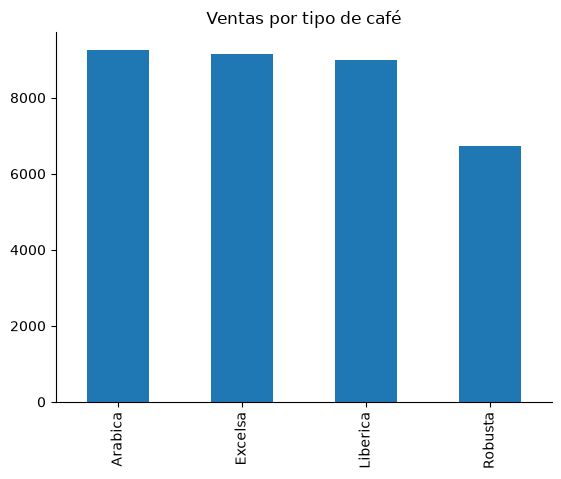

In [75]:
coffee_types.plot('Coffee Type Name', 'Total Sales', kind= 'bar', legend= False)
plt.title('Ventas por tipo de café')
plt.xlabel('')
sns.despine()
plt.show()

#### Ciudades con más membresías
Las principales ciudades son Washington, Nueva York y Saint Louis, en Estados Unidos. 

In [105]:
countries= df_customers.groupBy('Country', 'Loyalty Card').count()
countries.orderBy(col('Country').desc()).show()

+--------------+------------+-----+
|       Country|Loyalty Card|count|
+--------------+------------+-----+
| United States|          No|  402|
| United States|         Yes|  380|
|United Kingdom|          No|   41|
|United Kingdom|         Yes|   27|
|       Ireland|          No|   70|
|       Ireland|         Yes|   80|
+--------------+------------+-----+



In [ ]:
# Las 5 ciudades principales 
df_cities= df_customers.filter(col('Loyalty Card') == 'Yes').groupBy('City', 'Country').count().orderBy(col('count').desc())
df_cities.show(5)

+-------------+-------------+-----+
|         City|      Country|count|
+-------------+-------------+-----+
|   Washington|United States|   16|
|New York City|United States|    7|
|  Saint Louis|United States|    7|
|    Charlotte|United States|    6|
|   Sacramento|United States|    6|
+-------------+-------------+-----+
only showing top 5 rows



In [107]:
# Conversión de dataframe de Spark a dataframe de Pandas
countries= countries.toPandas()

In [108]:
countries_pivot= countries.pivot(index= 'Country', columns= 'Loyalty Card', values= 'count')
countries_pivot

Loyalty Card,No,Yes
Country,,
Ireland,70,80
United Kingdom,41,27
United States,402,380


In [109]:
countries_pivot= countries_pivot.reset_index()
countries_pivot

Loyalty Card,Country,No,Yes
0,Ireland,70,80
1,United Kingdom,41,27
2,United States,402,380


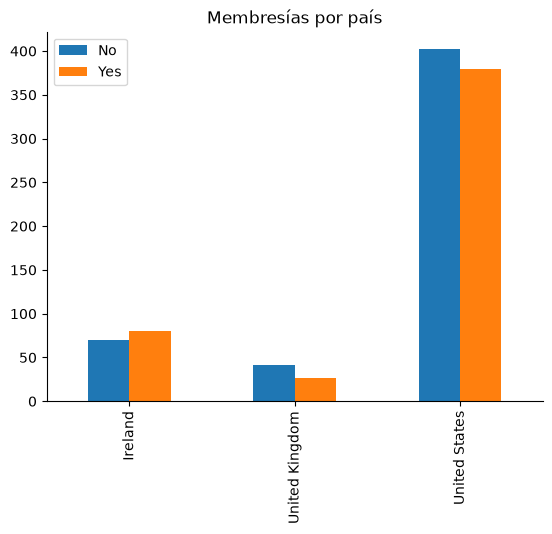

In [140]:
countries_pivot.plot(x='Country', kind= 'bar', legend= True)
plt.title('Membresías por país')
plt.xlabel('')
plt.legend(title= '')
sns.despine()
plt.show()


#### Unidades vendidas

In [20]:
# Unidades vendidas
coffee_types_quantity= df_products_orders.groupBy('Coffee Type Name', 'Roast Type Name').agg(F.sum('Quantity').alias('Total_units'),
                                                                                             F.sum('Sales').alias('Total sales')).orderBy(col('Total sales').desc())
coffee_types_quantity.show()

+----------------+---------------+-----------+------------------+
|Coffee Type Name|Roast Type Name|Total_units|       Total sales|
+----------------+---------------+-----------+------------------+
|         Excelsa|          Light|      239.0|3608.6299200057983|
|         Arabica|         Medium|      261.0|3397.5599842071533|
|        Liberica|          Light|      229.0|3330.1900787353516|
|         Arabica|          Light|      206.0| 3299.769968032837|
|        Liberica|           Dark|      214.0| 3254.410002708435|
|         Excelsa|         Medium|      184.0|2858.7099990844727|
|         Excelsa|           Dark|      219.0| 2686.469977378845|
|         Robusta|          Light|      234.0|2660.1799821853638|
|         Arabica|           Dark|      262.0| 2560.239999294281|
|        Liberica|         Medium|      200.0|2402.2800102233887|
|         Robusta|           Dark|      232.0|2124.8399815559387|
|         Robusta|         Medium|      196.0|1941.3200027942657|
+---------

In [ ]:
# Conversión a dataframe de Pandas
coffee_types_quantity= coffee_types_quantity.toPandas()

In [ ]:
coffee_types_quantity

,Coffee Type Name,Roast Type Name,Total_units,Total sales
0,Excelsa,Light,239.0,3608.629920
1,Arabica,Medium,261.0,3397.559984
2,Liberica,Light,229.0,3330.190079
3,Arabica,Light,206.0,3299.769968
4,Liberica,Dark,214.0,3254.410003
5,Excelsa,Medium,184.0,2858.709999
6,Excelsa,Dark,219.0,2686.469977
7,Robusta,Light,234.0,2660.179982
8,Arabica,Dark,262.0,2560.239999
9,Liberica,Medium,200.0,2402.280010


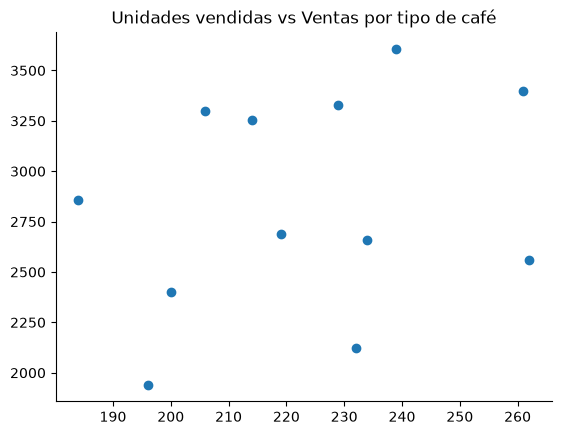

In [ ]:
# Diagrama de puntos de unidades vendidas vs ventas 
plt.scatter(coffee_types_quantity['Total_units'], coffee_types_quantity['Total sales'])
plt.title('Unidades vendidas vs Ventas por tipo de café')
plt.xlabel('')
sns.despine()
plt.show()

<b>Observaciones</b>
- Las variantes Arabica oscura, Arabica media y Excelsa claro cuentan con más unidades vendidas.
-  La mayor parte de productos no generan las ventas suficientes a mayores unidades vendidas: Productos muy baratos respecto a otros.
-  Las variantes <b>Excelsa</b> y <b>Liberica</b> generan la mayor parte de las ventas.
-  Entre los productos menos costosos están: café Arabica oscura, Robusta clara y Robusta Oscura.

#### Precio promedio por producto

In [37]:
df_products_orders.groupBy('Coffee Type Name').agg(F.avg('Unit Price').alias('Avg Price')).orderBy(col('Avg Price').desc()).show()

+----------------+------------------+
|Coffee Type Name|         Avg Price|
+----------------+------------------+
|        Liberica|14.625631688770495|
|         Excelsa| 14.49978374790501|
|         Arabica|12.547029627431737|
|         Robusta|10.439197768502057|
+----------------+------------------+



#### Margen de beneficio

In [40]:
# Beneficio total
coffee_types_profit= df_products_orders.groupBy('Coffee Type Name', 'Roast Type Name').agg(F.sum('Sales').alias('Total sales'),
                                                                                           F.sum('Total profit').alias('Total_profit')).orderBy(col('Total_profit').desc())
coffee_types_profit.show()

+----------------+---------------+------------------+------------------+
|Coffee Type Name|Roast Type Name|       Total sales|      Total_profit|
+----------------+---------------+------------------+------------------+
|        Liberica|          Light|3330.1900787353516| 432.9110517501831|
|        Liberica|           Dark| 3254.410002708435|   423.06355458498|
|         Excelsa|          Light|3608.6299200057983| 396.9404996037483|
|         Excelsa|         Medium|2858.7099990844727| 314.4487520456314|
|        Liberica|         Medium|2402.2800102233887| 312.2866485118866|
|         Arabica|         Medium|3397.5599842071533|305.77499201893806|
|         Arabica|          Light| 3299.769968032837| 296.9693987965584|
|         Excelsa|           Dark| 2686.469977378845| 295.5001568198204|
|         Arabica|           Dark| 2560.239999294281|230.41214448213577|
|         Robusta|          Light|2660.1799821853638|159.60419768095016|
|         Robusta|           Dark|2124.839981555938

In [41]:
# Margen de beneficio
coffee_types_profit= coffee_types_profit.withColumn('Profit_Rate', round(col('Total_profit') / col('Total sales') *100, 2)).orderBy(col('Profit_Rate').desc(), col('Total sales').desc())
coffee_types_profit.show()

+----------------+---------------+------------------+------------------+-----------+
|Coffee Type Name|Roast Type Name|       Total sales|      Total_profit|Profit_Rate|
+----------------+---------------+------------------+------------------+-----------+
|        Liberica|          Light|3330.1900787353516| 432.9110517501831|       13.0|
|        Liberica|           Dark| 3254.410002708435|   423.06355458498|       13.0|
|        Liberica|         Medium|2402.2800102233887| 312.2866485118866|       13.0|
|         Excelsa|          Light|3608.6299200057983| 396.9404996037483|       11.0|
|         Excelsa|         Medium|2858.7099990844727| 314.4487520456314|       11.0|
|         Excelsa|           Dark| 2686.469977378845| 295.5001568198204|       11.0|
|         Arabica|         Medium|3397.5599842071533|305.77499201893806|        9.0|
|         Arabica|          Light| 3299.769968032837| 296.9693987965584|        9.0|
|         Arabica|           Dark| 2560.239999294281|230.41214448

In [42]:
# Conversión a dataframe de Pandas
coffee_types_profit= coffee_types_profit.toPandas()

In [43]:
coffee_types_profit

,Coffee Type Name,Roast Type Name,Total sales,Total_profit,Profit_Rate
0,Liberica,Light,3330.190079,432.911052,13.0
1,Liberica,Dark,3254.410003,423.063555,13.0
2,Liberica,Medium,2402.280010,312.286649,13.0
3,Excelsa,Light,3608.629920,396.940500,11.0
4,Excelsa,Medium,2858.709999,314.448752,11.0
5,Excelsa,Dark,2686.469977,295.500157,11.0
6,Arabica,Medium,3397.559984,305.774992,9.0
7,Arabica,Light,3299.769968,296.969399,9.0
8,Arabica,Dark,2560.239999,230.412144,9.0
9,Robusta,Light,2660.179982,159.604198,6.0


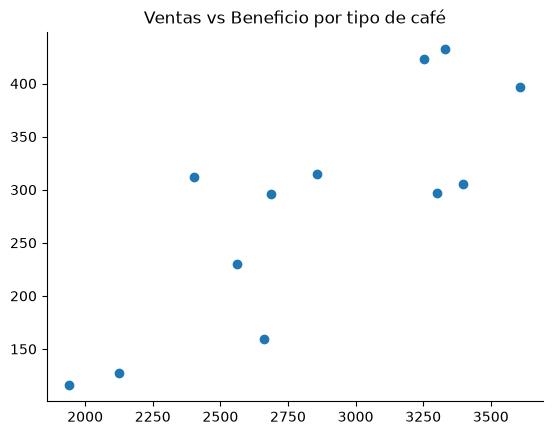

In [45]:
# Diagrama de puntos de ventas vs beneficio
plt.scatter(coffee_types_profit['Total sales'], coffee_types_profit['Total_profit'])
plt.title('Ventas vs Beneficio por tipo de café')
plt.xlabel('')
sns.despine()
plt.show()

In [ ]:
# Filtro para realizar gráfico de barras
margin_plot= coffee_types_profit[['Coffee Type Name', 'Total sales', 'Profit_Rate']]
margin_plot

,Coffee Type Name,Total sales,Profit_Rate
0,Liberica,3330.190079,13.0
1,Liberica,3254.410003,13.0
2,Liberica,2402.280010,13.0
3,Excelsa,3608.629920,11.0
4,Excelsa,2858.709999,11.0
5,Excelsa,2686.469977,11.0
6,Arabica,3397.559984,9.0
7,Arabica,3299.769968,9.0
8,Arabica,2560.239999,9.0
9,Robusta,2660.179982,6.0


In [ ]:
# Comparación del margen de beneficio por variante de café
margin_plot= coffee_types_profit.groupby('Coffee Type Name')['Profit_Rate'].mean()
margin_plot= margin_plot.reset_index()
margin_plot

,Coffee Type Name,Profit_Rate
0,Arabica,9.0
1,Excelsa,11.0
2,Liberica,13.0
3,Robusta,6.0


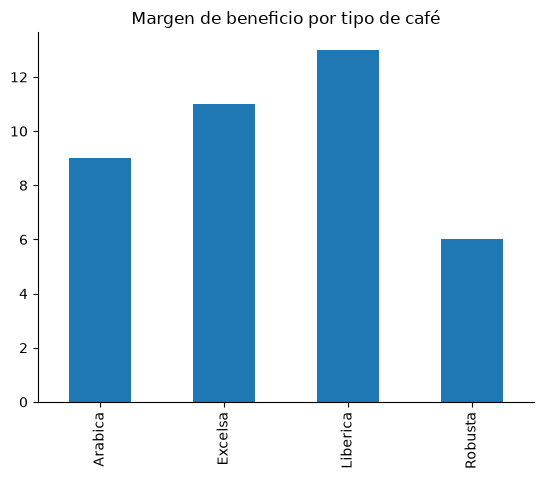

In [ ]:
# Gráfico de barras del margen de beneficio
margin_plot.plot(x= 'Coffee Type Name', kind= 'bar', legend= False)
plt.title('Margen de beneficio por tipo de café')
plt.xlabel('')
sns.despine()
plt.show()

<b>Observaciones</b>
- Algunos productos no generan los beneficios suficientes respecto a otros.
- Mientras que Arabica medio y Excelsa claro generan las mayores ventas, <b>Liberica</b>, en todas sus variantes de tostado genera la mayor rentabilidad relativa (margen de beneficio de 13%). 
